In [2]:
! pip install tensorflow pandas numpy matplotlib seaborn scikit-learn pillow 

Defaulting to user installation because normal site-packages is not writeable


DEPRECATION: Loading egg at c:\program files\python311\lib\site-packages\vboxapi-1.0-py3.11.egg is deprecated. pip 24.3 will enforce this behaviour change. A possible replacement is to use pip for package installation.. Discussion can be found at https://github.com/pypa/pip/issues/12330

[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import os
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf 

from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error,mean_absolute_error

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D,MaxPooling2D,Flatten,Dense

print(tf.__version__)

2.15.0


In [4]:
import os 
import pandas as pd

csv_path = "D:\DL\datasets\datasets\car-sim-data-master\driving_log.csv"

columns = ["center","left","right","steering","throttle","brake","speed"]
df = pd.read_csv(csv_path,header=None,names=columns)
print(df.head())
print(df.shape)

                                              center  \
0  /home/drdumbenstein/Udemy Slf Driing Car DL/Si...   
1  /home/drdumbenstein/Udemy Slf Driing Car DL/Si...   
2  /home/drdumbenstein/Udemy Slf Driing Car DL/Si...   
3  /home/drdumbenstein/Udemy Slf Driing Car DL/Si...   
4  /home/drdumbenstein/Udemy Slf Driing Car DL/Si...   

                                                left  \
0   /home/drdumbenstein/Udemy Slf Driing Car DL/S...   
1   /home/drdumbenstein/Udemy Slf Driing Car DL/S...   
2   /home/drdumbenstein/Udemy Slf Driing Car DL/S...   
3   /home/drdumbenstein/Udemy Slf Driing Car DL/S...   
4   /home/drdumbenstein/Udemy Slf Driing Car DL/S...   

                                               right  steering  throttle  \
0   /home/drdumbenstein/Udemy Slf Driing Car DL/S...       0.0       0.0   
1   /home/drdumbenstein/Udemy Slf Driing Car DL/S...       0.0       0.0   
2   /home/drdumbenstein/Udemy Slf Driing Car DL/S...       0.0       0.0   
3   /home/drdumbenstei

In [5]:
print(df.info())
print(df.describe())
print(df.isnull().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4914 entries, 0 to 4913
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   center    4914 non-null   object 
 1   left      4914 non-null   object 
 2   right     4914 non-null   object 
 3   steering  4914 non-null   float64
 4   throttle  4914 non-null   float64
 5   brake     4914 non-null   float64
 6   speed     4914 non-null   float64
dtypes: float64(4), object(3)
memory usage: 268.9+ KB
None
         steering     throttle        brake        speed
count  4914.00000  4914.000000  4914.000000  4914.000000
mean     -0.01207     0.931697     0.023780    28.630330
std       0.30264     0.248743     0.149285     5.621248
min      -1.00000     0.000000     0.000000     0.000068
25%       0.00000     1.000000     0.000000    30.149015
50%       0.00000     1.000000     0.000000    30.184310
75%       0.00000     1.000000     0.000000    30.206437
max       1.00000     1.0000

In [6]:
df = df.sample(n=30,random_state=42).reset_index(drop=True)
print(len(df))

30


Text(0, 0.5, 'Frequency')

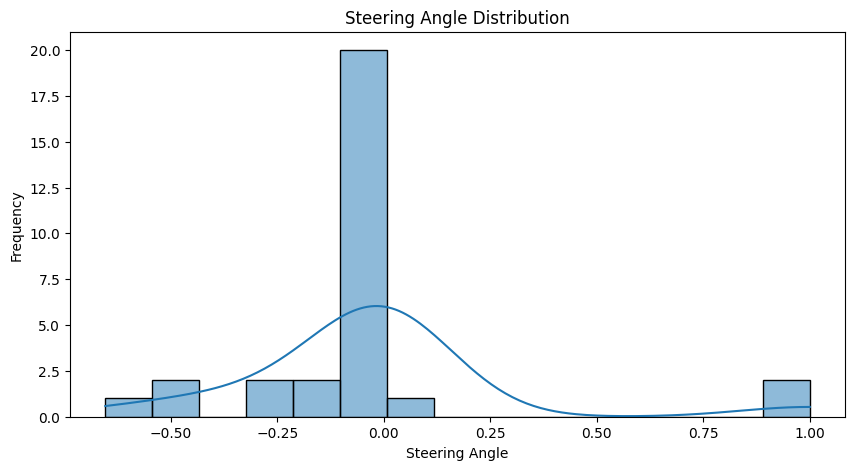

In [7]:
plt.figure(figsize=(10,5))
sns.histplot(df["steering"],bins=15,kde=True)
plt.title("Steering Angle Distribution")
plt.xlabel("Steering Angle")
plt.ylabel("Frequency")

In [14]:
import cv2 

X = []
y = []

img_dir = "D:\DL\datasets\datasets\car-sim-data-master\IMG"
for i in range(len(df)):
    img_name = os.path.basename(df["center"].iloc[i])
    img_path = os.path.join(img_dir,img_name)
    img = cv2.imread(img_path)

    if img is not None:
        img = cv2.resize(img,(64,64))
        img = img/255.0

        X.append(img)
        y.append(df["steering"].iloc[i])
X = np.array(X,dtype=np.float32)
y = np.array(y,dtype=np.float32)

print(X.shape)
print(y.shape)

(30, 64, 64, 3)
(30,)


In [15]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42)
print(len(X_train))
print(len(X_test))

24
6


In [17]:
model = Sequential([
    Conv2D(16,(3,3),activation="relu",input_shape = (64,64,3)),
    MaxPooling2D(2,2),
    Conv2D(32,(3,3),activation="relu"),
    MaxPooling2D(2,2),
    Flatten(),
    Dense(64,activation="relu"),
    Dense(1,activation="linear")
])
model.compile(

    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)
model.summary()




Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d (Conv2D)             (None, 62, 62, 16)        448       
                                                                 
 max_pooling2d (MaxPooling2  (None, 31, 31, 16)        0         
 D)                                                              
                                                                 
 conv2d_1 (Conv2D)           (None, 29, 29, 32)        4640      
                                                                 
 max_pooling2d_1 (MaxPoolin  (None, 14, 14, 32)        0         
 g2D)                                                            
                                                                 
 flatten (Flatten)           (None, 6272)              0         
                                                                 
 dense (Dense)               (None, 64)              

In [18]:
history = model.fit(
    X_train,
    y_train,
    epochs=2,
    batch_size=4,
    validation_data = (X_test,y_test)
)

Epoch 1/2


6/6 [==============================] - 1s 43ms/step - loss: 0.1804 - mae: 0.2854 - val_loss: 0.0588 - val_mae: 0.1484
Epoch 2/2
6/6 [==============================] - 0s 12ms/step - loss: 0.0873 - mae: 0.1824 - val_loss: 0.0702 - val_mae: 0.1591


In [19]:
loss,mae = model.evaluate(X_test,y_test)
print(loss)
print(mae)

1/1 [==============================] - 0s 25ms/step - loss: 0.0702 - mae: 0.1591
0.07021181285381317
0.15909147262573242
